# Estudio de precios de tarjetas de crédito — SIMBAD

**Materia:** Ciencia de Datos · **Fuente:** API de Estadísticas del Sistema Financiero v2
(SIMBAD) de la Superintendencia de Bancos de la República Dominicana.

**Pregunta:** ¿cuesta lo mismo el mismo cargo de una tarjeta de crédito en todas las
entidades? Y si no, ¿la diferencia la explica la gama de la tarjeta (clásica, oro,
platino) o el banco que la cobra?

Este notebook recorre, paso a paso, todo lo que hace la página **Precios de tarjetas** de
la app, desde la conexión al API hasta los filtros de búsqueda de tarjetas de crédito y
el análisis del cargo que le toca a cada grupo:

1. Librerías y parámetros
2. Conexión al API: clave, sesión HTTP y primera llamada
3. ¿Hasta qué mes hay datos?
4. Descarga completa con paginación
5. Exploración inicial (EDA)
6. Calidad de datos: registros repetidos
7. Limpieza
8. Filtros de búsqueda de tarjetas de crédito
9. Análisis del cargo del grupo
10. ¿Qué explica el precio: la gama o el banco?
11. Verificación contra la app
12. Exportar y reproducir
13. Resumen para la presentación

Desde la sección 9 todo el análisis es **sólo del cargo elegido**, igual que la página de
la app cuando se elige un cargo: ningún otro servicio entra en las cifras.

> **Cómo usarlo:** cambia `CARGO` en la celda de parámetros y ejecuta
> *Kernel → Restart Kernel and Run All Cells*. La descarga tarda alrededor de un minuto.

## 1. Librerías y parámetros

In [1]:
import json
import os
import sys
import time
import tomllib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3})

# El notebook vive en notebooks/; la raíz del proyecto es la carpeta de arriba.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
print("pandas", pd.__version__, "| requests", requests.__version__)

pandas 3.0.5 | requests 2.34.2


In [2]:
# ===== Parámetros del análisis: cámbialos y vuelve a ejecutar todo =====
CARGO = "Cargo por Renovación"   # la variable que analiza el grupo (campo `concepto`)
MONEDA = "DOP"                    # "DOP" o "USD"
TIPOS_ENTIDAD = []                # [] = todos; p. ej. ["BM"] = sólo bancos múltiples
PERIODO = None                    # None = el último mes publicado; o un mes, "2026-05"

ENDPOINT_URL = "https://apis.sb.gob.do/estadisticas/v2/tasas-comisiones/tarjetas-credito"
TIPOS_ACEPTADOS = ["BM", "AAyP", "BAyC"]   # este conjunto rechaza CC y EP (HTTP 400)
REGISTROS_POR_PAGINA = 1000

## 2. Conexión al API

### 2.1 La clave de suscripción

El API exige una clave que se obtiene en <https://desarrollador.sb.gob.do> y viaja en la
cabecera `Ocp-Apim-Subscription-Key`. **Nunca se escribe en el código**: se lee de la
variable de entorno `SIMBAD_API_KEY` o del mismo archivo que usa la app,
`.streamlit/secrets.toml`, que está en `.gitignore` y no se sube al repositorio.

In [3]:
def leer_clave() -> str:
    """Clave del API: primero la variable de entorno, luego el secrets.toml de la app."""
    clave = os.environ.get("SIMBAD_API_KEY", "").strip()
    if clave:
        return clave
    secretos = RAIZ / ".streamlit" / "secrets.toml"
    if secretos.exists():
        with secretos.open("rb") as archivo:
            return str(tomllib.load(archivo).get("simbad", {}).get("api_key", "")).strip()
    return ""


API_KEY = leer_clave()
if not API_KEY:
    raise RuntimeError("Falta la clave: define SIMBAD_API_KEY o crea .streamlit/secrets.toml")
print(f"Clave cargada ({len(API_KEY)} caracteres). No se imprime: es un secreto.")

Clave cargada (32 caracteres). No se imprime: es un secreto.


### 2.2 La sesión HTTP

Una `requests.Session` reutiliza la conexión entre llamadas y lleva las cabeceras fijas.
Dos detalles aprendidos con el API real:

- Delante del API hay un firewall (Sucuri) que **bloquea las peticiones sin
  `User-Agent`**; por eso se envía uno propio.
- En redes corporativas que inspeccionan HTTPS, `truststore` hace que Python use los
  certificados de Windows, **sin desactivar la verificación**.

`consultar()` reintenta hasta tres veces cuando el gateway corta la conexión o responde
con un error 5xx, que con este API pasa a menudo bajo carga.

In [4]:
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

sesion = requests.Session()
sesion.headers.update(
    {
        "Ocp-Apim-Subscription-Key": API_KEY,
        "Accept": "application/json",
        "User-Agent": "simbad-notebook/1.0",
    }
)


def consultar(params: list[tuple[str, str]], intentos: int = 3) -> requests.Response:
    """GET al endpoint de tarjetas, con reintentos ante cortes del gateway."""
    for intento in range(1, intentos + 1):
        try:
            respuesta = sesion.get(ENDPOINT_URL, params=params, timeout=120)
            if respuesta.status_code < 500:
                return respuesta
        except (requests.ConnectionError, requests.Timeout):
            if intento == intentos:
                raise
        time.sleep(2**intento)
    return respuesta


def parametros(periodo: str, pagina: int = 1, registros: int = REGISTROS_POR_PAGINA):
    """Parámetros de la consulta. Los filtros de lista van repetidos:
    tipoEntidad=BM&tipoEntidad=AAyP (separados por comas, el API responde 400)."""
    return (
        [("periodoInicial", periodo), ("periodoFinal", periodo)]
        + [("tipoEntidad", t) for t in TIPOS_ACEPTADOS]
        + [("paginas", str(pagina)), ("registros", str(registros))]
    )

### 2.3 Primera llamada: anatomía de una respuesta

Se piden tres registros de un mes de hace un año, que seguro está publicado. Observa que
la clave **no aparece en la URL**: va en la cabecera. La cabecera `x-pagination` dice
cuántos registros y páginas tiene la consulta completa.

In [5]:
mes_prueba = str(pd.Timestamp.today().to_period("M") - 12)
respuesta = consultar(parametros(mes_prueba, registros=3))

print("URL:", respuesta.url)
print("HTTP", respuesta.status_code, "en", respuesta.elapsed.total_seconds(), "segundos")
print("x-pagination:", json.dumps(json.loads(respuesta.headers.get("x-pagination", "{}")), indent=2))
print("Primer registro:")
print(json.dumps(respuesta.json()[0], indent=2, ensure_ascii=False))

URL: https://apis.sb.gob.do/estadisticas/v2/tasas-comisiones/tarjetas-credito?periodoInicial=2025-11&periodoFinal=2025-11&tipoEntidad=BM&tipoEntidad=AAyP&tipoEntidad=BAyC&paginas=1&registros=3
HTTP 200 en 2.86845 segundos
x-pagination: {
  "CurrentPage": 1,
  "RequestRecords": 3,
  "RecordsResponse": 3,
  "HasPrevious": false,
  "HasNext": true,
  "TotalRecords": 16180,
  "TotalPages": 5394
}
Primer registro:
{
  "periodo": "2025-11",
  "tipoEntidad": "BANCOS MÚLTIPLES",
  "entidad": "BANESCO",
  "nombreProducto": "Signature Business Personal",
  "marca": "Visa",
  "tipoTarjeta": "TARJETA DE CREDITO CORPORATIVA",
  "moneda": "DOP",
  "concepto": "Cargo por Renovación",
  "periodicidad": "ANUAL",
  "formatoTarifa": "Monto Fijo",
  "valor": 1500,
  "valorMinimo": 0,
  "valorMaximo": 0,
  "unidadValor": "DOP"
}


### 2.4 Lo que el API rechaza

Probar los errores también es parte de conocer la fuente. Sin filtro de entidad, o con un
tipo de entidad que este conjunto no publica, el API no devuelve datos.

In [6]:
casos = {
    "Sin tipoEntidad ni entidad": [("periodoInicial", mes_prueba), ("periodoFinal", mes_prueba), ("registros", "3")],
    "tipoEntidad=CC (corporaciones)": [("periodoInicial", mes_prueba), ("periodoFinal", mes_prueba),
                                        ("tipoEntidad", "CC"), ("registros", "3")],
    "tipoEntidad=BM,AAyP (con comas)": [("periodoInicial", mes_prueba), ("periodoFinal", mes_prueba),
                                         ("tipoEntidad", "BM,AAyP"), ("registros", "3")],
}
for caso, params in casos.items():
    r = consultar(params)
    print(f"{caso:<34} → HTTP {r.status_code}: {r.text[:110]}")

Sin tipoEntidad ni entidad         → HTTP 400: {"Succeeded":false,"Message":"Se debe introducir entidad o tipo de entidad.","Errors":null,"Data":null}
tipoEntidad=CC (corporaciones)     → HTTP 400: {"Succeeded":false,"Message":"Se introdujo un tipo de entidad incorrecto o faltan caracteres.","Errors":null,"


tipoEntidad=BM,AAyP (con comas)    → HTTP 400: {"Succeeded":false,"Message":"Se introdujo un tipo de entidad incorrecto o faltan caracteres.","Errors":null,"


## 3. ¿Hasta qué mes hay datos?

Cada conjunto de datos del API se publica con su propio rezago. Se sondea mes a mes hacia
atrás desde hoy, pidiendo sólo cinco registros, hasta encontrar el primer mes con datos.
Es lo mismo que hace la app para limitar los selectores de período.

In [7]:
def ultimo_periodo(meses_atras: int = 15) -> tuple[str, pd.DataFrame]:
    """Primer mes con datos, buscando hacia atrás desde el mes actual."""
    hoy = pd.Timestamp.today().to_period("M")
    sondeo = []
    for atras in range(meses_atras):
        mes = str(hoy - atras)
        r = consultar(parametros(mes, registros=5))
        cuerpo = r.json() if r.status_code == 200 else []
        filas = len(cuerpo) if isinstance(cuerpo, list) else 0
        sondeo.append({"periodo": mes, "http": r.status_code, "registros": filas})
        if filas:
            return mes, pd.DataFrame(sondeo)
    raise RuntimeError(f"Ningún mes con datos en los últimos {meses_atras} meses")


ultimo, sondeo = ultimo_periodo()
display(sondeo)
PERIODO = PERIODO or ultimo
print("Último mes publicado:", ultimo, "| Período que se analiza:", PERIODO)

,periodo,http,registros
0,2026-11,200,0
1,2026-10,200,0
2,2026-09,200,0
3,2026-08,200,0
4,2026-07,200,0
5,2026-06,200,0
6,2026-05,200,5


Último mes publicado: 2026-05 | Período que se analiza: 2026-05


## 4. Descarga completa con paginación

El API entrega los datos por páginas (`paginas` = número de página, `registros` = tamaño).
Se recorre página a página mientras la cabecera `x-pagination` diga `HasNext: true`.

In [8]:
def descargar(periodo: str) -> pd.DataFrame:
    """Tarifario completo de un mes, página por página."""
    lotes, pagina, inicio = [], 1, time.perf_counter()
    while True:
        r = consultar(parametros(periodo, pagina=pagina))
        r.raise_for_status()
        lote = r.json()
        info = json.loads(r.headers.get("x-pagination", "{}"))
        lotes.append(pd.DataFrame(lote))
        print(f"  página {pagina:>2} de {info.get('TotalPages', '?')}: {len(lote):>5} registros")
        if not info.get("HasNext") or not lote:
            break
        pagina += 1
    datos = pd.concat(lotes, ignore_index=True)
    segundos = time.perf_counter() - inicio
    print(f"{len(datos):,} registros en {pagina} páginas y {segundos:.1f} s "
          f"(el API anunció {info.get('TotalRecords', '?')}).")
    return datos


crudo = descargar(PERIODO)
crudo.shape

  página  1 de 17:  1000 registros


  página  2 de 17:  1000 registros


  página  3 de 17:  1000 registros


  página  4 de 17:  1000 registros


  página  5 de 17:  1000 registros


  página  6 de 17:  1000 registros


... (8 outputs left out)

  página 15 de 17:  1000 registros


  página 16 de 17:  1000 registros


  página 17 de 17:   362 registros
16,362 registros en 17 páginas y 34.7 s (el API anunció 16362).


(16362, 14)

## 5. Exploración inicial (EDA)

In [9]:
crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 16362 entries, 0 to 16361
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   periodo         16362 non-null  str  
 1   tipoEntidad     16362 non-null  str  
 2   entidad         16362 non-null  str  
 3   nombreProducto  16362 non-null  str  
 4   marca           16362 non-null  str  
 5   tipoTarjeta     16362 non-null  str  
 6   moneda          16362 non-null  str  
 7   concepto        16362 non-null  str  
 8   periodicidad    16362 non-null  str  
 9   formatoTarifa   16362 non-null  str  
 10  valor           16362 non-null  int64
 11  valorMinimo     16362 non-null  int64
 12  valorMaximo     16362 non-null  int64
 13  unidadValor     16362 non-null  str  
dtypes: int64(3), str(11)
memory usage: 4.2 MB


In [10]:
crudo.head()

,periodo,tipoEntidad,entidad,nombreProducto,marca,tipoTarjeta,moneda,concepto,periodicidad,formatoTarifa,valor,valorMinimo,valorMaximo,unidadValor
0,2026-05,BANCOS MÚLTIPLES,BANESCO,Corporativa,Visa,TARJETA DE CREDITO CORPORATIVA,DOP,"Cargo por Cobertura Seguro (por Pérdida, falsificación o Robo)",ANUAL,Monto Fijo,750,0,0,DOP
1,2026-05,BANCOS MÚLTIPLES,BANESCO,Signature Business,Visa,TARJETA DE CREDITO CORPORATIVA,DOP,"Cargo por Cobertura Seguro (por Pérdida, falsificación o Robo)",ANUAL,Monto Fijo,750,0,0,DOP
2,2026-05,BANCOS MÚLTIPLES,BANESCO,Signature Business Empleado,Visa,TARJETA DE CREDITO CORPORATIVA,DOP,"Cargo por Cobertura Seguro (por Pérdida, falsificación o Robo)",ANUAL,Monto Fijo,750,0,0,DOP
3,2026-05,BANCOS MÚLTIPLES,BANESCO,Signature Business Normal,Visa,TARJETA DE CREDITO CORPORATIVA,DOP,"Cargo por Cobertura Seguro (por Pérdida, falsificación o Robo)",ANUAL,Monto Fijo,750,0,0,DOP
4,2026-05,BANCOS MÚLTIPLES,POPULAR,VISA EXCELSA,Visa,TARJETA DE CREDITO CORPORATIVA,DOP,Interés por financiamiento,MENSUAL,Porcentaje,8,0,0,%


In [11]:
crudo[["valor", "valorMinimo", "valorMaximo"]].describe()

,valor,valorMinimo,valorMaximo
count,"16,362.00","16,362.00","16,362.00"
mean,603.27,29.36,68.30
std,"1,685.84",132.38,302.97
min,0.00,0.00,0.00
25%,6.00,0.00,0.00
50%,75.00,0.00,0.00
75%,700.00,0.00,0.00
max,"40,000.00","3,750.00","7,500.00"


In [12]:
print("Entidades:", crudo["entidad"].nunique(), "| Conceptos (tipos de cargo):", crudo["concepto"].nunique())
for columna in ["tipoEntidad", "tipoTarjeta", "marca", "moneda", "formatoTarifa", "unidadValor", "periodicidad"]:
    print(f"\n--- {columna}")
    print(crudo[columna].value_counts().to_string())

Entidades: 23 | Conceptos (tipos de cargo): 25

--- tipoEntidad
tipoEntidad
BANCOS MÚLTIPLES                       15291
ASOCIACIONES DE AHORROS Y PRÉSTAMOS     1005
BANCOS DE AHORRO Y CRÉDITO                66

--- tipoTarjeta
tipoTarjeta
TARJETA DE CREDITO PERSONAL CLASICA/STANDARD                                    5828
TARJETA DE CREDITO PERSONAL PLATINO/PLATINUM (O SUPERIOR)                       4642
TARJETA DE CREDITO PERSONAL ORO/GOLD                                            3559
TARJETA DE CREDITO EMPRESARIAL                                                  1172
TARJETA DE CREDITO CORPORATIVA                                                   414
TARJETA DE CREDITO DISTRIBUCION/SUPLIDOR                                         256
TARJETA DE CREDITO EMPRESARIAL FLOTILLA                                          221
TARJETA DE CREDITO PERSONAL FLOTILLA                                             157
PRÉSTAMOS A TRAVÉS DE LÍNEAS DE CRÉDITO PERSONALES (CRÉDITOS DIFERIDOS ETC.)    

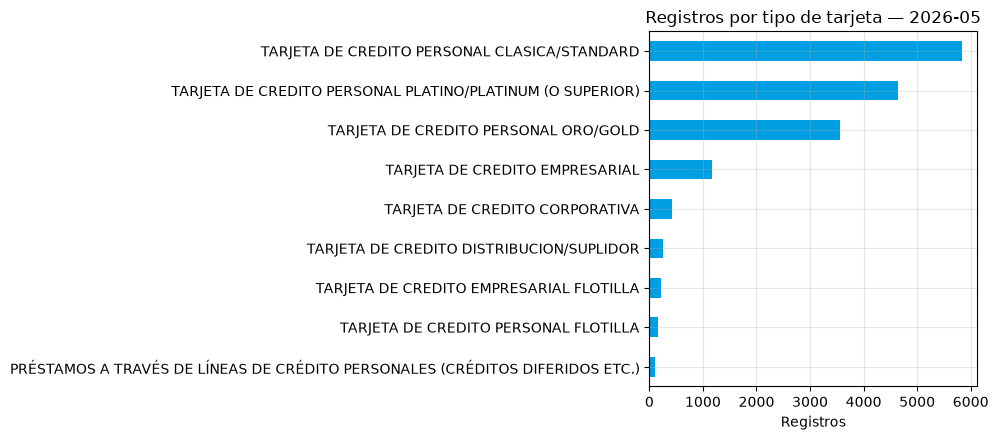

In [13]:
conteo = crudo["tipoTarjeta"].value_counts().sort_values()
ax = conteo.plot.barh(color="#009FE3", figsize=(10, 4.5))
ax.set_title(f"Registros por tipo de tarjeta — {PERIODO}")
ax.set_xlabel("Registros")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 6. Calidad de datos: registros repetidos

El API anuncia más registros de los que realmente son distintos: hay filas **idénticas en
todas sus columnas** (misma entidad, producto, cargo y valor) repetidas varias veces. Si no
se quitan, un producto repetido diez veces pesaría diez veces más en cualquier promedio.

In [14]:
repetidas = crudo.duplicated()
print(f"Filas repetidas: {repetidas.sum():,} de {len(crudo):,} ({repetidas.mean():.1%})")

veces = crudo.groupby(list(crudo.columns), dropna=False).size()
display(veces.value_counts().sort_index().rename_axis("veces que aparece").to_frame("filas distintas").T)

tarifario = crudo.drop_duplicates().reset_index(drop=True)
print(f"Registros únicos: {len(tarifario):,}")

Filas repetidas: 7,417 de 16,362 (45.3%)


veces que aparece,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
filas distintas,7254,442,127,103,156,268,321,101,70,24,10,20,3,9,8,10,19


Registros únicos: 8,945


¿Y si fuera un defecto de la paginación? Para descartarlo se pide **el mes entero en una
sola página** (`registros=20000`) y se compara: si salen las mismas filas, las
repeticiones vienen del propio API y no de cómo se recorrieron las páginas.

In [15]:
r = consultar(parametros(PERIODO, registros=20000))
una_pagina = pd.DataFrame(r.json())
print(f"Una sola página: {len(una_pagina):,} filas, {len(una_pagina.drop_duplicates()):,} únicas "
      f"en {r.elapsed.total_seconds():.1f} s")

clave = lambda df: set(map(tuple, df.astype(str)[sorted(df.columns)].drop_duplicates().to_numpy()))
print("¿Mismas filas únicas que la descarga paginada?", clave(una_pagina) == clave(crudo))

Una sola página: 16,362 filas, 8,945 únicas en 11.1 s


¿Mismas filas únicas que la descarga paginada? True


## 7. Limpieza

1. Valores numéricos como números y textos sin espacios sobrantes.
2. **Escalas de valores fijos:** algunas filas no declaran un precio único sino un rango
   (`formatoTarifa = "Escala de valores fijos"`): su `valor` viene en cero y el precio está
   en `valorMinimo`–`valorMaximo`. Se apartan en vez de mezclarlas.
3. Se descartan las filas con precio cero.

In [16]:
tarifario[["valor", "valorMinimo", "valorMaximo"]] = tarifario[["valor", "valorMinimo", "valorMaximo"]].apply(
    pd.to_numeric, errors="coerce"
)
for columna in ["tipoEntidad", "entidad", "tipoTarjeta", "concepto", "unidadValor", "moneda"]:
    tarifario[columna] = tarifario[columna].astype(str).str.strip()

es_rango = tarifario["valorMinimo"].fillna(0) > 0
rangos = tarifario[es_rango]
precios = tarifario[~es_rango & (tarifario["valor"] > 0)]

print(f"Filas con escala de valores (apartadas): {len(rangos):,} ({len(rangos) / len(tarifario):.1%})")
print(f"Filas con precio cero (descartadas):     {(~es_rango & (tarifario['valor'] <= 0)).sum():,}")
print(f"Filas con precio único y positivo:       {len(precios):,}")
rangos[["entidad", "concepto", "tipoTarjeta", "valorMinimo", "valorMaximo", "unidadValor"]].head()

Filas con escala de valores (apartadas): 292 (3.3%)
Filas con precio cero (descartadas):     1
Filas con precio único y positivo:       8,652


,entidad,concepto,tipoTarjeta,valorMinimo,valorMaximo,unidadValor
264,BHD,Cargo por Cheque Devuelto,TARJETA DE CREDITO CORPORATIVA,450,1000,DOP
265,BHD,Costo de Carta de Saldo,TARJETA DE CREDITO CORPORATIVA,150,300,DOP
404,BDI,Cargo por Renovación,TARJETA DE CREDITO EMPRESARIAL,800,1500,DOP
405,BDI,Cargo por Renovación,TARJETA DE CREDITO EMPRESARIAL,3000,7000,DOP
406,BDI,Cargo por Renovación,TARJETA DE CREDITO EMPRESARIAL,3000,7000,DOP


## 8. Filtros de búsqueda de tarjetas de crédito

Se aplican en el mismo orden que la página de la app, y se cuenta cuántos registros
quedan tras cada uno (un **embudo**):

1. **Tipo de entidad** (opcional).
2. **Moneda:** comparar pesos con dólares mediría el tipo de cambio, no precios.
3. **Gama:** sólo las tres tarjetas personales comparables entre sí —clásica, oro y
   platino—; fuera quedan corporativas, empresariales y de flotilla.
4. **Tipo de cargo:** la variable del grupo (`CARGO`).
5. **Unidad:** un mismo cargo puede publicarse como porcentaje o como monto fijo, y no se
   pueden promediar entre sí.

In [17]:
GAMAS = {
    "TARJETA DE CREDITO PERSONAL CLASICA/STANDARD": "Clásica",
    "TARJETA DE CREDITO PERSONAL ORO/GOLD": "Oro",
    "TARJETA DE CREDITO PERSONAL PLATINO/PLATINUM (O SUPERIOR)": "Platino",
}
ORDEN_GAMAS = ["Clásica", "Oro", "Platino"]
CODIGOS = {
    "BANCOS MÚLTIPLES": "BM",
    "ASOCIACIONES DE AHORROS Y PRÉSTAMOS": "AAyP",
    "BANCOS DE AHORRO Y CRÉDITO": "BAyC",
}

embudo = [("Tarifario descargado (filas únicas)", len(tarifario)), ("Con precio único y positivo", len(precios))]
filtrado = precios
if TIPOS_ENTIDAD:
    filtrado = filtrado[filtrado["tipoEntidad"].map(CODIGOS).isin(TIPOS_ENTIDAD)]
    embudo.append((f"Tipo de entidad: {', '.join(TIPOS_ENTIDAD)}", len(filtrado)))
filtrado = filtrado[filtrado["moneda"] == MONEDA]
embudo.append((f"Moneda: {MONEDA}", len(filtrado)))
personales = filtrado[filtrado["tipoTarjeta"].isin(GAMAS)].assign(gama=lambda d: d["tipoTarjeta"].map(GAMAS))
embudo.append(("Tarjetas personales clásica, oro y platino", len(personales)))
print(f"{len(personales):,} registros de {personales['entidad'].nunique()} entidades")

5,395 registros de 23 entidades


Los tipos de cargo disponibles con estos filtros —de aquí sale el valor de `CARGO`—:

In [18]:
catalogo = (
    personales.groupby("concepto")
    .agg(
        entidades=("entidad", "nunique"),
        registros=("valor", "size"),
        unidades=("unidadValor", lambda s: ", ".join(sorted(s.unique()))),
    )
    .sort_values("entidades", ascending=False)
)
display(catalogo)
assert CARGO in catalogo.index, f"«{CARGO}» no aparece con estos filtros: elige uno de la tabla."

,entidades,registros,unidades
concepto,,,
Comisión por Avance Efectivo,23,480,%
Cargo por Renovación,21,402,DOP
Comisión por Mora,21,467,"%, DOP"
Cargo por Reemplazo por Deterioro Plástico,21,368,DOP
Comisión por Sobregiro,21,440,"%, DOP"
Interés por financiamiento,21,644,%
"Cargo por Cobertura Seguro (por Pérdida, falsificación o Robo)",19,423,DOP
Cargo por Emisión de Principal,19,334,DOP
Cargo por Emisión de Adicional,17,315,DOP


,filtro,registros
0,Tarifario descargado (filas únicas),8945
1,Con precio único y positivo,8652
2,Moneda: DOP,6554
3,"Tarjetas personales clásica, oro y platino",5395
4,Cargo: Cargo por Renovación,402
5,Unidad: DOP,402


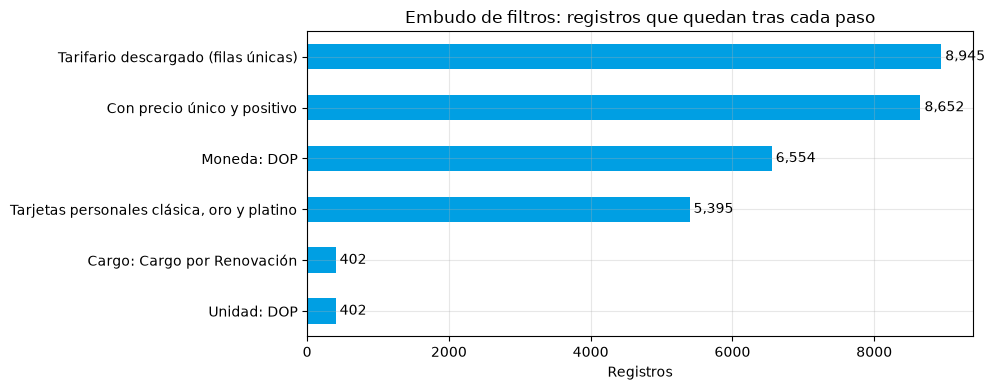

In [19]:
del_cargo = personales[personales["concepto"] == CARGO]
embudo.append((f"Cargo: {CARGO}", len(del_cargo)))

unidades = del_cargo["unidadValor"].value_counts()
UNIDAD = unidades.index[0]   # la más frecuente, como en la app
if len(unidades) > 1:
    print(f"Atención: este cargo se publica en {list(unidades.index)}; se analiza {UNIDAD}.")
del_cargo = del_cargo[del_cargo["unidadValor"] == UNIDAD]
embudo.append((f"Unidad: {UNIDAD}", len(del_cargo)))

embudo = pd.DataFrame(embudo, columns=["filtro", "registros"])
display(embudo)

ax = embudo.iloc[::-1].plot.barh(x="filtro", y="registros", legend=False, color="#009FE3", figsize=(10, 4))
ax.set_title("Embudo de filtros: registros que quedan tras cada paso")
ax.set_xlabel("Registros")
ax.set_ylabel("")
for i, valor in enumerate(embudo["registros"].iloc[::-1]):
    ax.text(valor, i, f" {valor:,}", va="center")
plt.tight_layout()
plt.show()

## 9. Análisis del cargo del grupo

### 9.1 Una observación por entidad y gama

Una entidad puede publicar el mismo cargo en varias tarjetas de la misma gama (Visa y
Mastercard, por ejemplo). Para que no pese más por eso, su precio en cada gama es **la
mediana** de lo que publicó.

In [20]:
por_entidad = del_cargo.groupby(["tipoEntidad", "entidad", "gama"])["valor"].median().reset_index()
print(f"{len(por_entidad)} observaciones (entidad × gama) de {por_entidad['entidad'].nunique()} entidades")
por_entidad.head(10)

57 observaciones (entidad × gama) de 21 entidades


,tipoEntidad,entidad,gama,valor
0,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,ALAVER,Clásica,900.00
1,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,ALAVER,Oro,"1,500.00"
2,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,ALAVER,Platino,"2,500.00"
3,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,APAP,Clásica,995.00
4,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,APAP,Oro,"1,600.00"
5,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,APAP,Platino,"8,000.00"
6,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,BONAO,Clásica,625.00
7,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,BONAO,Oro,"1,000.00"
8,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,BONAO,Platino,"1,500.00"
9,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,CIBAO,Clásica,675.00


### 9.2 Estadística descriptiva por gama

Además de `describe()`: el **coeficiente de variación** (desviación estándar entre media,
en %) mide la dispersión sin depender de la escala, y **veces** dice cuántas veces el
precio más alto supera al más bajo.

In [21]:
descriptiva = por_entidad.groupby("gama")["valor"].describe()
descriptiva["cv_%"] = descriptiva["std"] / descriptiva["mean"] * 100
descriptiva["veces"] = descriptiva["max"] / descriptiva["min"]
descriptiva = descriptiva.reindex([g for g in ORDEN_GAMAS if g in descriptiva.index])
descriptiva

,count,mean,std,min,25%,50%,75%,max,cv_%,veces
gama,,,,,,,,,,
Clásica,19.00,873.42,335.15,300.00,687.50,900.00,997.50,"1,900.00",38.37,6.33
Oro,19.00,"1,826.32","1,317.02",900.00,"1,200.00","1,550.00","1,625.00","6,400.00",72.11,7.11
Platino,19.00,"5,871.05","5,152.44","1,400.00","2,850.00","4,500.00","7,000.00","24,000.00",87.76,17.14


### 9.3 Distribución: diagrama de caja con un punto por entidad

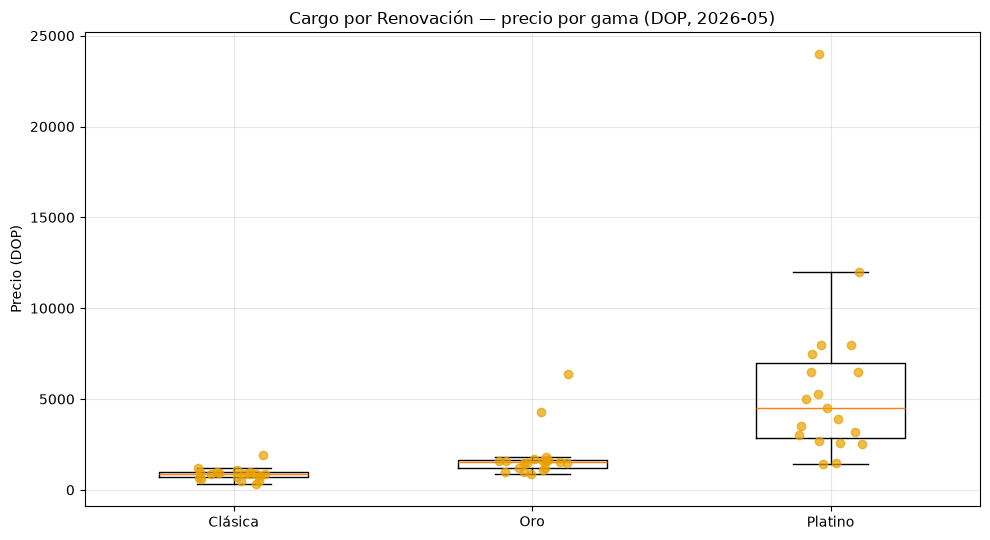

In [22]:
gamas = list(descriptiva.index)
grupos = [por_entidad.loc[por_entidad["gama"] == g, "valor"] for g in gamas]
azar = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.boxplot(grupos, tick_labels=gamas, showfliers=False, widths=0.5)
for i, valores in enumerate(grupos, start=1):
    ax.scatter(i + azar.uniform(-0.12, 0.12, len(valores)), valores, alpha=0.7, color="#E8A100", zorder=3)
ax.set_title(f"{CARGO} — precio por gama ({UNIDAD}, {PERIODO})")
ax.set_ylabel(f"Precio ({UNIDAD})")
plt.tight_layout()
plt.show()

### 9.4 Precio de cada entidad y cuánto multiplica entre gamas

Fijada la entidad, ¿cuánto sube el precio al pasar de clásica a platino? Si el precio
dependiera sólo del servicio, cada entidad cobraría lo mismo en las tres gamas.

17 entidades publican el cargo en todas las gamas. La típica cobra 5.9 veces más en su gama más cara que en la más barata; LA NACIONAL llega a 12.6 veces.


gama,Clásica,Oro,Platino,multiplica
entidad,,,,
LA NACIONAL,"1,900.00","4,300.00","24,000.00",12.63
APAP,995.00,"1,600.00","8,000.00",8.04
CARIBE,"1,000.00","1,600.00","8,000.00",8.00
CIBAO,675.00,"1,200.00","5,250.00",7.78
LAFISE,"1,000.00","1,650.00","7,500.00",7.50
POPULAR,900.00,"1,700.00","6,500.00",7.22
SANTA CRUZ,700.00,900.00,"5,000.00",7.14
BLH,500.00,"1,500.00","3,200.00",6.40
BANESCO,"1,100.00","1,800.00","6,500.00",5.91


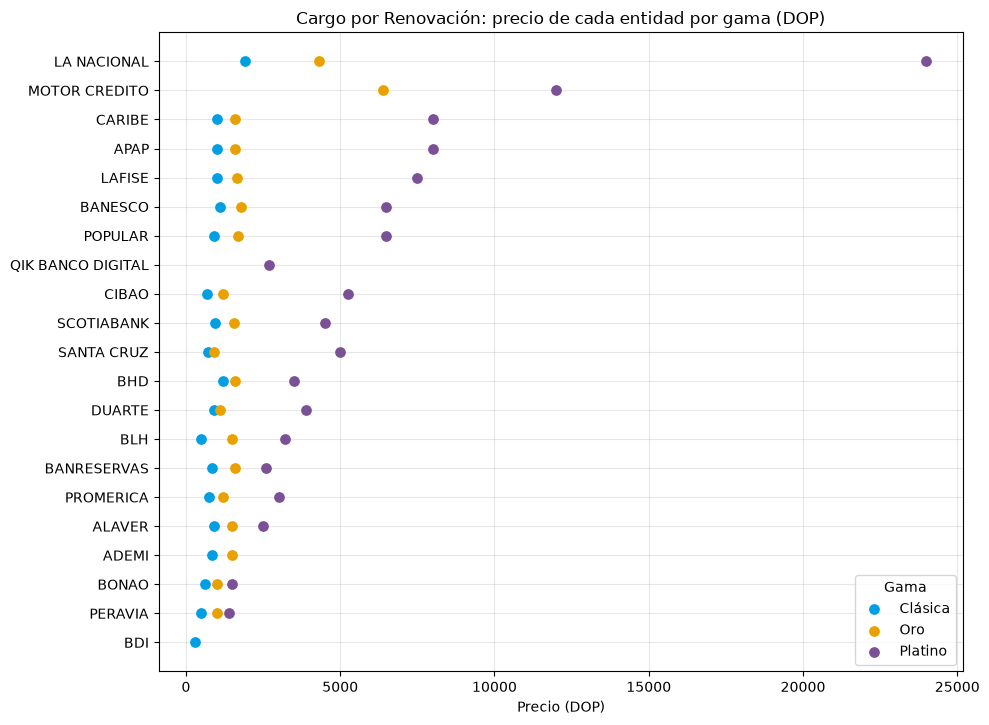

In [23]:
ancho = por_entidad.pivot_table(index="entidad", columns="gama", values="valor")[gamas]
ancho = ancho.loc[ancho.mean(axis=1).sort_values().index]

escalera = ancho.dropna().assign(multiplica=lambda d: d.max(axis=1) / d.min(axis=1))
escalera = escalera.sort_values("multiplica", ascending=False)
print(f"{len(escalera)} entidades publican el cargo en todas las gamas. La típica cobra "
      f"{escalera['multiplica'].median():.1f} veces más en su gama más cara que en la más barata; "
      f"{escalera.index[0]} llega a {escalera['multiplica'].iloc[0]:.1f} veces.")
display(escalera)

fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(ancho))))
for gama, color in zip(gamas, ["#009FE3", "#E8A100", "#7A5195"]):
    ax.scatter(ancho[gama], ancho.index, label=gama, color=color, s=45, zorder=3)
ax.set_title(f"{CARGO}: precio de cada entidad por gama ({UNIDAD})")
ax.set_xlabel(f"Precio ({UNIDAD})")
ax.legend(title="Gama")
plt.tight_layout()
plt.show()

### 9.5 Valores atípicos (regla de Tukey)

Un precio es atípico si cae fuera de **Q1 − 1.5·RIC** o **Q3 + 1.5·RIC** dentro de su
gama, donde RIC = Q3 − Q1. Es la misma regla con la que se dibujan los bigotes del
diagrama de caja.

In [24]:
cuartiles = por_entidad.groupby("gama")["valor"].quantile([0.25, 0.75]).unstack()
ric = cuartiles[0.75] - cuartiles[0.25]
vallas = pd.DataFrame({"valla_inferior": cuartiles[0.25] - 1.5 * ric, "valla_superior": cuartiles[0.75] + 1.5 * ric})
marcado = por_entidad.join(vallas, on="gama")
atipicos = marcado[(marcado["valor"] < marcado["valla_inferior"]) | (marcado["valor"] > marcado["valla_superior"])]
display(vallas)
print(f"{len(atipicos)} precios atípicos:")
atipicos

,valla_inferior,valla_superior
gama,,
Clásica,222.50,"1,462.50"
Oro,562.50,"2,262.50"
Platino,"-3,375.00","13,225.00"


4 precios atípicos:


,tipoEntidad,entidad,gama,valor,valla_inferior,valla_superior
15,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,LA NACIONAL,Clásica,"1,900.00",222.50,"1,462.50"
16,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,LA NACIONAL,Oro,"4,300.00",562.50,"2,262.50"
17,ASOCIACIONES DE AHORROS Y PRÉSTAMOS,LA NACIONAL,Platino,"24,000.00","-3,375.00","13,225.00"
21,BANCOS DE AHORRO Y CRÉDITO,MOTOR CREDITO,Oro,"6,400.00",562.50,"2,262.50"


### 9.6 ¿El precio cambia con la gama? Prueba de Friedman

La pregunta es si el precio del cargo difiere entre clásica, oro y platino. Las muestras
**no son independientes**: la misma entidad aparece en las tres gamas. Por eso no sirve
Kruskal-Wallis y se usa **Friedman**, la prueba no paramétrica para medidas repetidas,
con las entidades que publican el cargo en las tres gamas.

- H₀: el precio se distribuye igual en las tres gamas.
- H₁: al menos una gama tiene precios distintos.

In [25]:
completas = ancho.dropna()
print(f"Entidades con precio en las tres gamas: {len(completas)}")
if len(gamas) == 3 and len(completas) >= 3 and completas.nunique().sum() > 3:
    friedman = stats.friedmanchisquare(*[completas[g] for g in gamas])
    valor_p = "p < 0.0001" if friedman.pvalue < 0.0001 else f"p = {friedman.pvalue:.4f}"
    print(f"Friedman χ² = {friedman.statistic:.2f}, {valor_p}")
    print("Se rechaza H₀ (α = 0.05): el precio cambia con la gama." if friedman.pvalue < 0.05
          else "No se rechaza H₀ (α = 0.05): no hay evidencia de que el precio cambie con la gama.")
else:
    print("No hay datos suficientes para la prueba con este cargo.")

Entidades con precio en las tres gamas: 17
Friedman χ² = 34.00, p < 0.0001
Se rechaza H₀ (α = 0.05): el precio cambia con la gama.


## 10. ¿Qué explica el precio: la gama o el banco?

Se reparte la variación del precio entre los factores que podrían explicarla. Para cada
factor se calcula qué parte de la varianza desaparece al sustituir cada precio por la media
de su grupo (es el R² de un modelo de medias por grupo). Se trabaja con el **logaritmo del
precio** para que las diferencias sean relativas.

In [26]:
datos = del_cargo.assign(logp=np.log(del_cargo["valor"]))
total = ((datos["logp"] - datos["logp"].mean()) ** 2).sum()


def r2(por: list[str]) -> float:
    if total <= 0:
        return 0.0
    medias = datos.groupby(por)["logp"].transform("mean")
    return 1 - ((datos["logp"] - medias) ** 2).sum() / total


r2_gama = r2(["gama"])
r2_ambos = r2(["gama", "entidad"])
descomposicion = pd.DataFrame(
    {
        "factor": ["La gama", "…y además el banco", "Sin explicar"],
        "porcentaje": [r2_gama * 100, (r2_ambos - r2_gama) * 100, (1 - r2_ambos) * 100],
    }
)
display(descomposicion)

,factor,porcentaje
0,La gama,58.71
1,…y además el banco,16.84
2,Sin explicar,24.45


## 11. Verificación contra la app

La app usa las funciones de `simbad/estudio_tarjetas.py` y el cliente `simbad/client.py`.
Aquí se comprueba que el código escrito a mano en este notebook da **exactamente** las
mismas cifras que la app. Si algo no coincidiera, la celda fallaría.

In [27]:
from simbad import estudio_tarjetas as estudio
from simbad.client import SimbadClient

assert estudio.GAMAS == GAMAS and estudio.ORDEN_GAMAS == ORDEN_GAMAS

pd.testing.assert_frame_equal(estudio.precio_por_entidad(del_cargo), por_entidad)

de_la_app = estudio.estadistica_por_gama(por_entidad).set_index("gama")
np.testing.assert_allclose(
    de_la_app[["media", "desviacion", "minimo", "mediana", "maximo", "cv", "veces"]].to_numpy(),
    descriptiva[["mean", "std", "min", "50%", "max", "cv_%", "veces"]].to_numpy(),
)
assert abs(estudio.explica(datos, ["gama"]) - r2_gama) < 1e-12
assert abs(estudio.explica(datos, ["gama", "entidad"]) - r2_ambos) < 1e-12
assert set(estudio.atipicos(por_entidad)["entidad"]) == set(atipicos["entidad"])

cliente = SimbadClient(API_KEY)
filas, informe = cliente.fetch_raw(
    "TasasComisionesTarjetasCredito", PERIODO, PERIODO, filters={"tipoEntidad": TIPOS_ACEPTADOS}, page_size=20000
)
assert len(filas) == len(crudo.drop_duplicates())

print("OK: precio por entidad, estadística descriptiva, descomposición y atípicos coinciden con la app.")
print(f"OK: el cliente de la app descarga los mismos {len(filas):,} registros únicos.")

OK: precio por entidad, estadística descriptiva, descomposición y atípicos coinciden con la app.
OK: el cliente de la app descarga los mismos 8,945 registros únicos.


## 12. Exportar y reproducir

In [28]:
salidas = RAIZ / "notebooks" / "salidas"
salidas.mkdir(exist_ok=True)
nombre = "".join(c if c.isalnum() else "_" for c in CARGO)[:40] + f"_{PERIODO}_{MONEDA}"

del_cargo.to_csv(salidas / f"{nombre}_registros.csv", index=False, encoding="utf-8-sig")
por_entidad.to_csv(salidas / f"{nombre}_por_entidad.csv", index=False, encoding="utf-8-sig")
descriptiva.to_csv(salidas / f"{nombre}_descriptiva.csv", encoding="utf-8-sig")
print("Guardado en notebooks/salidas/:", *sorted(p.name for p in salidas.glob(f"{nombre}*")), sep="\n  ")

Guardado en notebooks/salidas/:
  Cargo_por_Renovación_2026-05_DOP_descriptiva.csv
  Cargo_por_Renovación_2026-05_DOP_por_entidad.csv
  Cargo_por_Renovación_2026-05_DOP_registros.csv


In [29]:
url = requests.Request("GET", ENDPOINT_URL, params=parametros(PERIODO)).prepare().url
print("La misma consulta desde una terminal (sustituye TU_CLAVE por la tuya):\n")
print(f'curl -H "Ocp-Apim-Subscription-Key: TU_CLAVE" "{url}"')

La misma consulta desde una terminal (sustituye TU_CLAVE por la tuya):

curl -H "Ocp-Apim-Subscription-Key: TU_CLAVE" "https://apis.sb.gob.do/estadisticas/v2/tasas-comisiones/tarjetas-credito?periodoInicial=2026-05&periodoFinal=2026-05&tipoEntidad=BM&tipoEntidad=AAyP&tipoEntidad=BAyC&paginas=1&registros=1000"


## 13. Resumen para la presentación

Las medidas de dispersión se dan **dentro de cada gama**: comparar una clásica barata con
una platino cara mediría la gama, no al banco.

In [30]:
por_gama = lambda columna, formato: ", ".join(f"{g.lower()} {v:{formato}}" for g, v in descriptiva[columna].items())
print(f"""Cargo analizado: {CARGO} ({UNIDAD}), {PERIODO}, moneda {MONEDA}.

- Lo publican {por_entidad['entidad'].nunique()} entidades en tarjetas personales.
- Precio mediano por gama ({UNIDAD}): {por_gama('50%', ',.2f')}.
- Del más barato al más caro, dentro de cada gama: {por_gama('veces', '.1f')} veces.
- Coeficiente de variación por gama (%): {por_gama('cv_%', '.1f')}.
- Dentro de la misma entidad, la gama más cara cuesta {escalera['multiplica'].median():.1f} veces la más barata (mediana de {len(escalera)} entidades).
- La gama explica {r2_gama * 100:.1f} % de la variación del precio; saber el banco añade {(r2_ambos - r2_gama) * 100:.1f} %.
- Valores atípicos (Tukey): {len(atipicos)}{': ' + ', '.join(atipicos['entidad'] + ' (' + atipicos['gama'] + ')') if len(atipicos) else ''}.""")

Cargo analizado: Cargo por Renovación (DOP), 2026-05, moneda DOP.

- Lo publican 21 entidades en tarjetas personales.
- Precio mediano por gama (DOP): clásica 900.00, oro 1,550.00, platino 4,500.00.
- Del más barato al más caro, dentro de cada gama: clásica 6.3, oro 7.1, platino 17.1 veces.
- Coeficiente de variación por gama (%): clásica 38.4, oro 72.1, platino 87.8.
- Dentro de la misma entidad, la gama más cara cuesta 5.9 veces la más barata (mediana de 17 entidades).
- La gama explica 58.7 % de la variación del precio; saber el banco añade 16.8 %.
- Valores atípicos (Tukey): 4: LA NACIONAL (Clásica), LA NACIONAL (Oro), LA NACIONAL (Platino), MOTOR CREDITO (Oro).


**Limitaciones que conviene decir en la presentación:**

- Es **precio de lista** (lo que la entidad publica), no lo que pagó un cliente concreto.
- Es una **foto de un mes**; no dice si la dispersión crece o se reduce con el tiempo.
- La descomposición de la varianza es **descriptiva**: mide asociación, no causa.
- Un banco caro en este cargo puede ser barato en otro: no es una recomendación.